In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
import pickle


In [38]:
data = pd.read_csv('complaintdata.csv') 

In [39]:
print(data.info())
print(data.head())
print(data['category'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id1             1064 non-null   int64  
 1   category        1064 non-null   object 
 2   details         1064 non-null   object 
 3   pnr             1064 non-null   object 
 4   startTime       1064 non-null   object 
 5   endTime         1064 non-null   object 
 6   status          1064 non-null   object 
 7   staffId         1046 non-null   object 
 8   ticket id       0 non-null      float64
 9    ticketDetails  18 non-null     object 
 10  feedback        1064 non-null   object 
 11  rating          1064 non-null   object 
 12  sentiment       1064 non-null   float64
 13  metadata        1064 non-null   object 
 14  media           1046 non-null   object 
dtypes: float64(2), int64(1), object(12)
memory usage: 124.8+ KB
None
   id1               category  \
0    1            damage_

In [40]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = re.sub(r'\W', ' ', text)  # Remove special characters
    text = text.lower()  # Lowercase
    text = ' '.join([lemmatizer.lemmatize(word) for word in text.split() if word not in stop_words])
    return text

data['processed_details'] = data['details'].apply(preprocess_text)

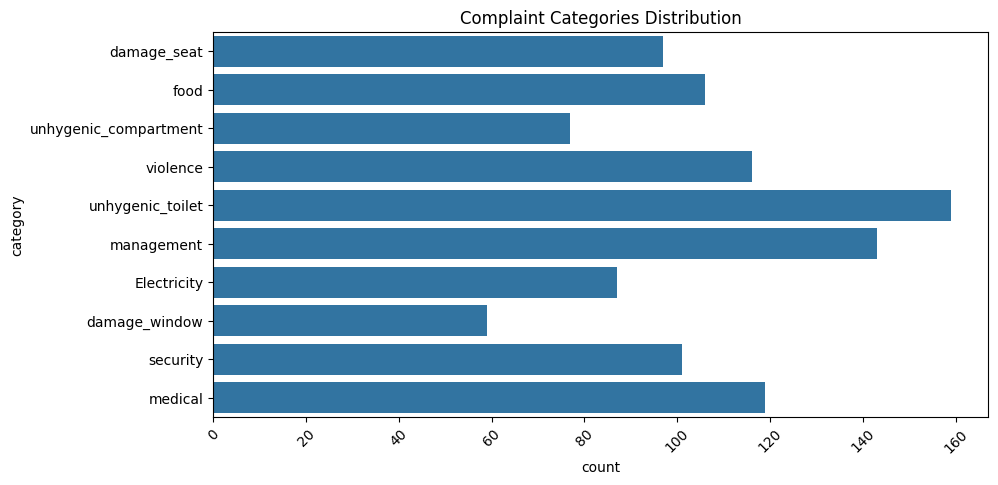

In [41]:
plt.figure(figsize=(10,5))
sns.countplot(data['category'])
plt.title('Complaint Categories Distribution')
plt.xticks(rotation=45)
plt.show()

In [42]:
label_encoder = LabelEncoder()
data['category_encoded'] = label_encoder.fit_transform(data['category'])

In [43]:
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(data['processed_details']).toarray()
y = data['category_encoded']

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

In [46]:
y_pred = model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       0.95      1.00      0.97        19
           2       1.00      0.92      0.96        12
           3       1.00      1.00      1.00        23
           4       1.00      0.91      0.95        33
           5       1.00      1.00      1.00        17
           6       0.95      1.00      0.97        18
           7       0.95      0.82      0.88        22
           8       0.87      1.00      0.93        26
           9       1.00      1.00      1.00        29

    accuracy                           0.96       213
   macro avg       0.96      0.96      0.96       213
weighted avg       0.96      0.96      0.96       213

Accuracy: 0.9624413145539906


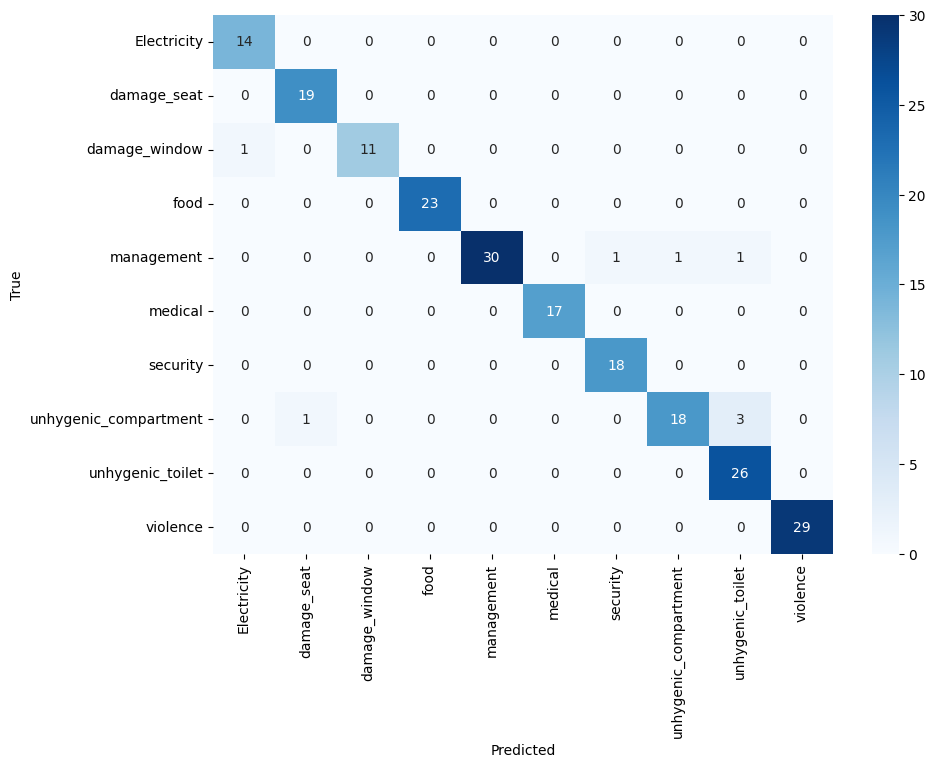

In [47]:

conf_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [48]:
with open('complaint_category_model.pkl', 'wb') as model_file:
    pickle.dump(model, model_file)

with open('tfidf_vectorizer.pkl', 'wb') as tfidf_file:
    pickle.dump(tfidf, tfidf_file)

with open('label_encoder.pkl', 'wb') as le_file:
    pickle.dump(label_encoder, le_file)
